# Óxidos: conceito e classificação
### Funções inorgânicas — óxidos

**Objetivo:** Classificar óxidos em básicos, ácidos, anfóteros e neutros e relacionar cada classe com o pH que produz na água.

### Como usar este notebook

Execute as células na ordem, de cima para baixo. As células Markdown apresentam os conceitos; as células de código fazem as contas e geram as visualizações com **RDKit**, **py3Dmol** e **Matplotlib**.

> **Moléculas em 3D:** clique na figura e **arraste o mouse** — ela gira em 360° em qualquer direção. Use a roda do mouse (ou dois dedos no celular) para dar zoom. As cores seguem a convenção dos químicos (C = cinza, H = branco, O = vermelho, N = azul, S = amarelo, Cl = verde, Na = violeta).

In [1]:
# @title Preparar o ambiente (só precisa rodar uma vez)
import importlib.util, subprocess, sys

def _tem(modulo):
    return importlib.util.find_spec(modulo) is not None

for pacote in ("rdkit", "py3Dmol"):
    if not _tem(pacote):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pacote], check=True)

import rdkit, py3Dmol
print("rdkit", rdkit.__version__, "| py3Dmol", py3Dmol.__version__)

rdkit 2026.09.2 | py3Dmol 3.0.0


## 1. Conceito principal

**Óxido** é o composto binário formado por **oxigênio** (no estado de oxidação $-2$) e outro elemento químico. A fórmula geral é

$$
\boxed{\mathrm{E_xO_y}}
$$

e a classificação depende do comportamento do óxido em água e com ácidos/bases:

| Classe | O que faz | Exemplos |
|---|---|---|
| **Óxido básico** | reage com ácido; metal + oxigênio | $\mathrm{Na_2O}$, $\mathrm{CaO}$, $\mathrm{MgO}$ |
| **Óxido ácido (anidrido)** | reage com base/água formando ácido | $\mathrm{CO_2}$, $\mathrm{SO_2}$, $\mathrm{SO_3}$, $\mathrm{N_2O_5}$ |
| **Óxido anfótero** | reage com ácido **e** com base | $\mathrm{Al_2O_3}$, $\mathrm{ZnO}$ |
| **Óxido neutro** | não reage com nenhum dos dois | $\mathrm{CO}$, $\mathrm{NO}$, $\mathrm{N_2O}$ |

As duas reações-chave da água são:

$$
\mathrm{Na_2O + H_2O \rightarrow 2NaOH}\quad\text{(básico)}
$$
$$
\mathrm{SO_3 + H_2O \rightarrow H_2SO_4}\quad\text{(ácido)}
$$

e a regra mnemônica do dia a dia: **metal + oxigênio = óxido básico** (ou anfótero, se o metal for Al/Zn); **ametal + oxigênio = óxido ácido** (com as exceções CO, NO, N₂O, que são neutros).

## 2. Exemplo resolvido passo a passo

**Quanto $\mathrm{CaO}$ (cal virgem) é preciso para neutralizar 1 kg de solo com acidez equivalente a $0{,}05\ \mathrm{mol}$ de $\mathrm{H^+}$?**

**Passo 1 — reação.**

$$
\mathrm{CaO + 2H^+ \rightarrow Ca^{2+} + H_2O}
$$

Um mol de $\mathrm{CaO}$ consome **dois** mols de $\mathrm{H^+}$ (o cálcio libera $\mathrm{Ca(OH)_2}$ ao reagir com a água do solo, e essa base é diprótica).

**Passo 2 — mols de CaO.**

$$
n = \frac{0{,}05}{2} = 0{,}025\ \mathrm{mol}
$$

**Passo 3 — massa ($M = 40{,}08 + 16{,}00 = 56{,}08\ \mathrm{g/mol}$).**

$$
m = n\,M = 0{,}025 \cdot 56{,}08 = \boxed{1{,}40\ \mathrm{g}}
$$

**Passo 4 — comparar com calcário ($\mathrm{CaCO_3}$, $M = 100{,}09$).**

$$
m = 0{,}025 \cdot 100{,}09 = 2{,}50\ \mathrm{g}
$$

O calcário precisa de quase o dobro da massa porque sua massa molar é maior — mas é mais barato e mais seguro de manusear. É a **calagem** que se faz na agricultura.

## 3. Conferindo o cálculo com Python

In [2]:
# @title Calagem: CaO x CaCO3
from rdkit import Chem
from rdkit.Chem import Descriptors

M_CAO = Descriptors.MolWt(Chem.MolFromSmiles("[Ca+2].[O-2]"))
M_CACO3 = Descriptors.MolWt(Chem.MolFromSmiles("[Ca+2].[O-]C(=O)[O-]"))

acidez = 0.05       # mol de H+ a neutralizar
protons_por_ca = 2  # CaO -> Ca(OH)2 -> 2 OH-

n_cao = acidez / protons_por_ca
print(f"M(CaO)    = {M_CAO:.2f} g/mol")
print(f"M(CaCO3)  = {M_CACO3:.2f} g/mol")
print(f"n(CaO)    = {n_cao:.3f} mol")
print(f"massa CaO   = {n_cao * M_CAO:.2f} g")
print(f"massa CaCO3 = {n_cao * M_CACO3:.2f} g")
print(f"poder neutralizante relativo (CaO/CaCO3) = {M_CACO3 / M_CAO:.2f}")

M(CaO)    = 56.08 g/mol
M(CaCO3)  = 100.09 g/mol
n(CaO)    = 0.025 mol
massa CaO   = 1.40 g
massa CaCO3 = 2.50 g
poder neutralizante relativo (CaO/CaCO3) = 1.78


## 4. Visualização

### 4.1 Óxido de cálcio em 3D — arraste para girar

O $\mathrm{CaO}$ é iônico: $\mathrm{Ca^{2+}}$ e $\mathrm{O^{2-}}$. É o pó branco da cal virgem, que "ferve" quando se joga água (reação exotérmica formando $\mathrm{Ca(OH)_2}$).

In [3]:
# @title Molécula 3D interativa — arraste com o mouse para girar 360°
from rdkit import Chem
from rdkit.Chem import AllChem
import py3Dmol

def molecula_3d(smiles, largura=680, altura=440):
    """SMILES -> visualização 3D interativa (arrastar = girar, roda = zoom)."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido: {smiles!r}")
    mol = Chem.AddHs(mol)                      # H explícitos: aparecem na figura

    parametros = AllChem.ETKDGv3()
    parametros.randomSeed = 0xC0FFEE           # mesmo desenho em toda execução
    if AllChem.EmbedMolecule(mol, parametros) != 0:
        raise RuntimeError(f"não foi possível gerar a geometria 3D de {smiles!r}")

    if AllChem.MMFFHasAllMoleculeParams(mol):
        AllChem.MMFFOptimizeMolecule(mol)      # relaxa a estrutura
    else:
        AllChem.UFFOptimizeMolecule(mol)       # cobre íons sem parâmetros MMFF

    visor = py3Dmol.view(width=largura, height=altura)
    visor.addModel(Chem.MolToMolBlock(mol), "mol")
    visor.setStyle({"stick": {"radius": 0.13, "colorscheme": "Jmol"},
                    "sphere": {"scale": 0.28, "colorscheme": "Jmol"}})
    visor.setBackgroundColor("#ffffff")
    visor.zoomTo()
    return visor

molecula_3d("[Ca+2].[O-2]")

[16:36:09] UFFTYPER: Unrecognized atom type: Ca+2 (0)
[16:36:09] UFFTYPER: Unrecognized atom type: Ca+2 (0)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.2 Dióxido de enxofre em 3D

O $\mathrm{SO_2}$ é um óxido **ácido** e angular (o enxofre tem um par de elétrons livres). É o gás do cheiro de fósforo queimado e o principal responsável pela chuva ácida.

In [4]:
molecula_3d("O=S=O")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.3 Os dois em 2D, com os risquinhos

Repare que o $\mathrm{CaO}$ fica com as duas cargas explícitas e o $\mathrm{SO_2}$ aparece com duas ligações duplas $\mathrm{S=O}$ — cada risco duplo é uma ligação dupla.

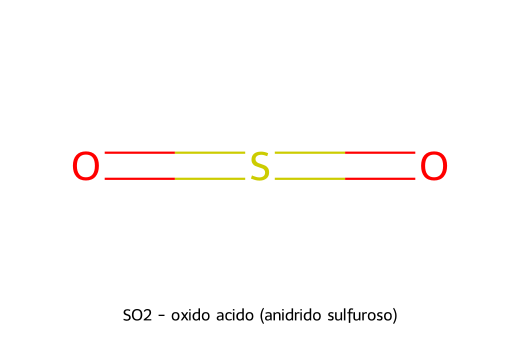

In [5]:
# @title Estrutura 2D com os risquinhos das ligações
from rdkit import Chem
from rdkit.Chem import rdDepictor
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG

rdDepictor.SetPreferCoordGen(True)   # layout 2D no estilo de livro didático

def estrutura_2d(smiles, legenda="", largura=520, altura=360, mostrar_h=False):
    """SMILES -> SVG. Um traço = simples, dois = dupla, três = tripla.

    A legenda fica em ASCII porque o desenho do RDKit corrompe acento e
    subscrito (para título bonito, use matplotlib).
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido: {smiles!r}")
    if mostrar_h:
        mol = Chem.AddHs(mol)
    rdDepictor.Compute2DCoords(mol)

    desenho = rdMolDraw2D.MolDraw2DSVG(largura, altura)
    desenho.drawOptions().bondLineWidth = 2.2
    desenho.drawOptions().padding = 0.10
    desenho.DrawMolecule(mol, legend=legenda)
    desenho.FinishDrawing()
    return SVG(desenho.GetDrawingText())

estrutura_2d("[Ca+2].[O-2]", legenda="CaO - oxido basico (cal virgem)")
estrutura_2d("O=S=O", legenda="SO2 - oxido acido (anidrido sulfuroso)")

### 4.4 Galeria: as quatro classes de óxidos

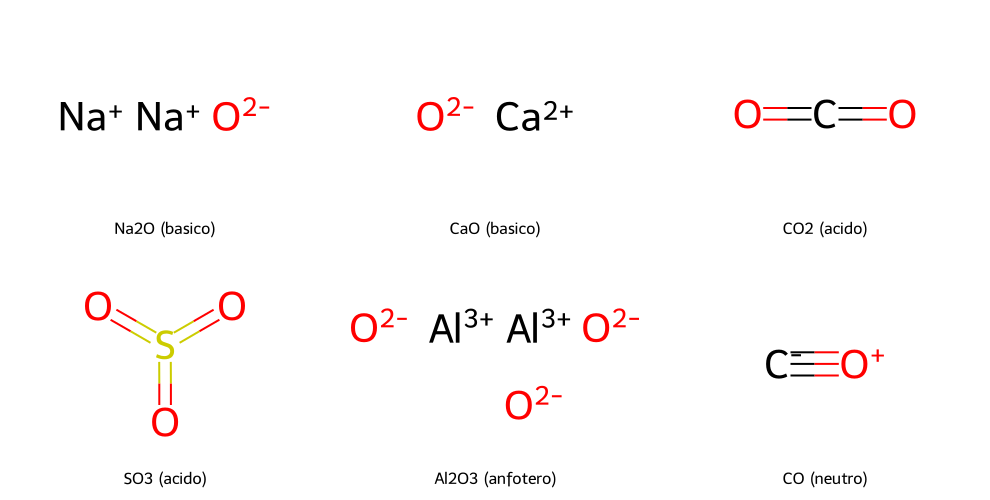

In [6]:
# @title Óxidos e suas classes
from rdkit import Chem
from rdkit.Chem import Draw
from IPython.display import SVG

oxidos = [
    ("Na2O (basico)", "[Na+].[Na+].[O-2]"),
    ("CaO (basico)", "[Ca+2].[O-2]"),
    ("CO2 (acido)", "O=C=O"),
    ("SO3 (acido)", "O=S(=O)=O"),
    ("Al2O3 (anfotero)", "[Al+3].[Al+3].[O-2].[O-2].[O-2]"),
    ("CO (neutro)", "[C-]#[O+]"),
]
imagem = Draw.MolsToGridImage([Chem.MolFromSmiles(s) for _, s in oxidos],
                              molsPerRow=3, subImgSize=(330, 250),
                              legends=[nome for nome, _ in oxidos], useSVG=True)
imagem if hasattr(imagem, "data") else SVG(imagem)

### 4.5 O que acontece com o pH ao borbulhar o óxido na água

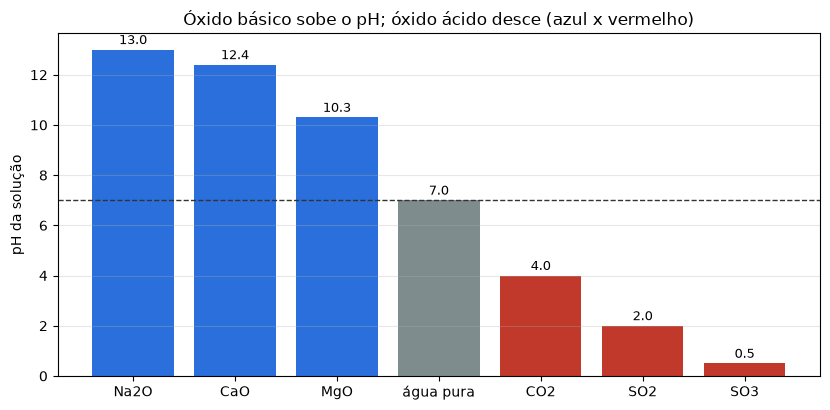

In [7]:
# @title pH resultante em água
import matplotlib.pyplot as plt

oxidos_ph = [
    ("Na2O", 13.0, "básico"), ("CaO", 12.4, "básico"), ("MgO", 10.3, "básico"),
    ("água pura", 7.0, "neutro"),
    ("CO2", 4.0, "ácido"), ("SO2", 2.0, "ácido"), ("SO3", 0.5, "ácido"),
]
nomes = [nome for nome, _, _ in oxidos_ph]
valores = [valor for _, valor, _ in oxidos_ph]
cores = {"básico": "#2a6fdb", "neutro": "#7f8c8d", "ácido": "#c0392b"}

plt.figure(figsize=(8.4, 4.2))
plt.bar(nomes, valores, color=[cores[classe] for _, _, classe in oxidos_ph])
for i, valor in enumerate(valores):
    plt.annotate(f"{valor:.1f}", (i, valor), xytext=(0, 4), textcoords="offset points",
                 ha="center", fontsize=9)
plt.axhline(7, color="#333", linestyle="--", linewidth=1)
plt.ylabel("pH da solução")
plt.title("Óxido básico sobe o pH; óxido ácido desce (azul x vermelho)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 4.6 A escala de acidez dos óxidos ácidos

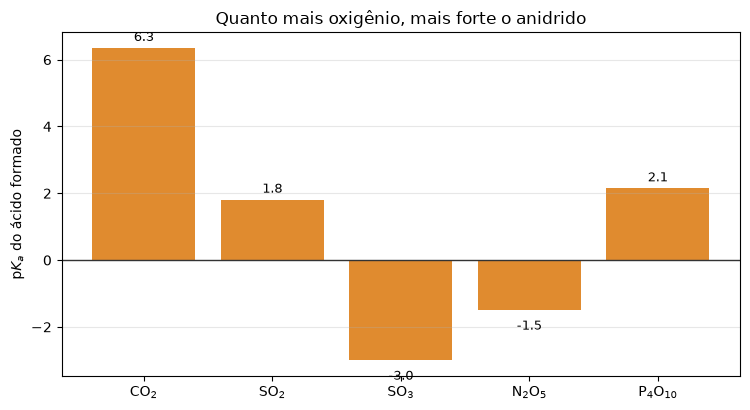

In [8]:
# @title Força dos anidridos
anidridos = ["CO$_2$", "SO$_2$", "SO$_3$", "N$_2$O$_5$", "P$_4$O$_{10}$"]
pka_acido_formado = [6.35, 1.81, -3.0, -1.5, 2.15]

plt.figure(figsize=(7.6, 4.2))
plt.bar(anidridos, pka_acido_formado, color="#e08b2f")
for i, valor in enumerate(pka_acido_formado):
    plt.annotate(f"{valor:.1f}", (i, valor), xytext=(0, 5 if valor > 0 else -14),
                 textcoords="offset points", ha="center", fontsize=9)
plt.axhline(0, color="#333", linewidth=1)
plt.ylabel("p$K_a$ do ácido formado")
plt.title("Quanto mais oxigênio, mais forte o anidrido")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Como interpretar o resultado

- A classe do óxido é decidida pelo **comportamento**, não pela fórmula: $\mathrm{Al_2O_3}$ parece básico mas reage com base também.
- Óxidos ácidos são chamados **anidridos** porque "sem água" eles formam o ácido correspondente: $\mathrm{SO_3}$ é o anidrido sulfúrico.
- O $\mathrm{CO}$ e o $\mathrm{NO}$ são neutros: não reagem com água nem com base. O CO é tóxico justamente porque não "é neutralizado" pelo organismo.
- A calagem usa óxido/hidróxido/carbonato de cálcio para subir o pH do solo — a conta do exemplo mostra por que se usa massa e não mol.

## 6. Exercício de fixação

Classifique os óxidos abaixo e escreva a reação com água (quando houver): $\mathrm{MgO}$, $\mathrm{N_2O_5}$, $\mathrm{ZnO}$, $\mathrm{NO}$.

In [9]:
# @title Exercício
classificacao = {
    "MgO": ("básico", "MgO + H2O -> Mg(OH)2"),
    "N2O5": ("ácido", "N2O5 + H2O -> 2 HNO3"),
    "ZnO": ("anfótero", "ZnO + 2HCl -> ZnCl2 + H2O | ZnO + 2NaOH -> Na2ZnO2 + H2O"),
    "NO": ("neutro", "não reage com água"),
}
for formula, (classe, reacao) in classificacao.items():
    print(f"{formula:6s} {classe:9s} {reacao}")

MgO    básico    MgO + H2O -> Mg(OH)2
N2O5   ácido     N2O5 + H2O -> 2 HNO3
ZnO    anfótero  ZnO + 2HCl -> ZnCl2 + H2O | ZnO + 2NaOH -> Na2ZnO2 + H2O
NO     neutro    não reage com água


## 7. Resumo

- Óxido = oxigênio (-2) + outro elemento.
- Básico (metal), ácido/anidrido (ametal), anfótero (Al, Zn), neutro (CO, NO, N₂O).
- Com água: óxido básico → hidróxido; óxido ácido → ácido.
- Quanto mais oxigênio no ametal, mais forte o ácido formado.
- Calagem: $\mathrm{CaO}$ neutraliza $\mathrm{H^+}$ do solo (2 mols de H⁺ por mol de CaO).

## Referências

- ATKINS, P.; JONES, L. *Princípios de Química*. Bookman.
- FELTRE, R. *Química Geral*. Moderna.
- IUPAC. *Nomenclature of Inorganic Chemistry* (Red Book).